In [1]:
import os
import time
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
import torchvision
from torchvision import transforms, models
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

print(f"Python: {__import__('sys').version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"Torchvision: {torchvision.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA version: {torch.version.cuda}")
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("WARNING: GPU is not available. Training will fall back to CPU and may be slow.")

# Sanity check tensor
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
x = torch.tensor([1.0, 2.0, 3.0], device=device)
print(f"\nTensor test on {device}: {x}")

Python: 3.12.10
PyTorch: 2.14.1+cu132
Torchvision: 0.29.1+cu132
CUDA available: True
CUDA version: 13.2
GPU name: NVIDIA GeForce RTX 5050 Laptop GPU
GPU memory: 8.55 GB

Tensor test on cuda: tensor([1., 2., 3.], device='cuda:0')


## 2. Reproducibility

In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(42)
print("Random seeds set to 42 for reproducibility.")

Random seeds set to 42 for reproducibility.


## 3. Dataset Configuration & Splitting
We use a stratified 80/10/10 split for Train, Validation, and Test sets.

Total images found: 18055
Number of classes: 20
Train size: 14444 (80%)
Val size: 1805 (10%)
Test size: 1806 (10%)


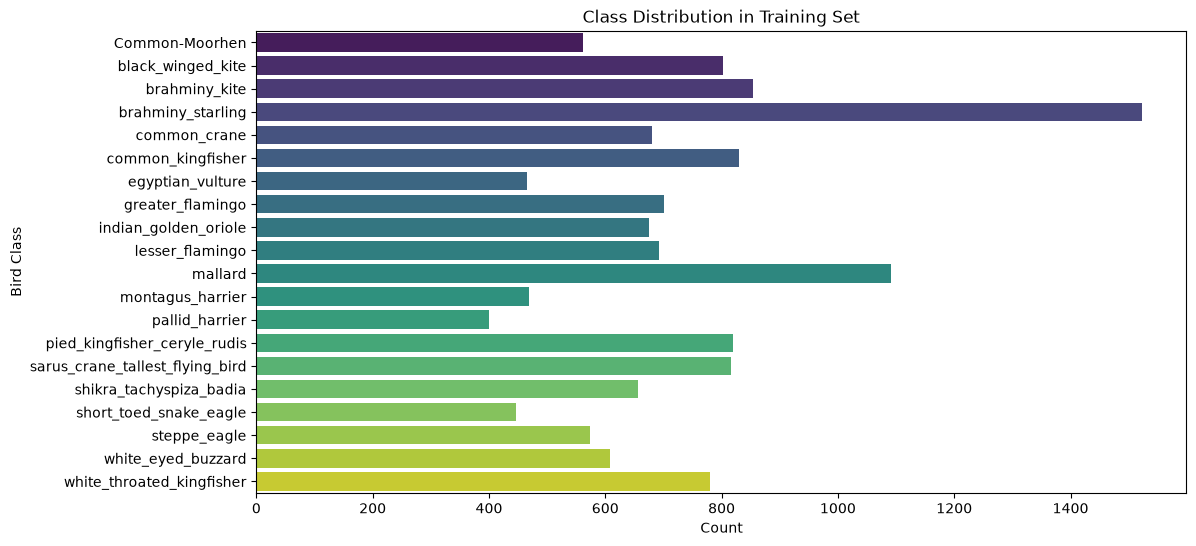

In [ ]:
DATA_DIR = r"C:\CodeWorld\DL\Master_Dataset_Cleaned_224"
BATCH_SIZE = 64
NUM_WORKERS = 0 
EPOCHS = 10 # 10 epochs demo #TODO: Do more epoch

full_dataset = ImageFolder(root=DATA_DIR)
targets = full_dataset.targets
class_names = full_dataset.classes
num_classes = len(class_names)

print(f"Total images found: {len(full_dataset)}")
print(f"Number of classes: {num_classes}")

train_idx, temp_idx = train_test_split(
    np.arange(len(full_dataset)),
    test_size=0.20,
    random_state=42,
    stratify=targets
)

temp_targets = [targets[i] for i in temp_idx]

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=temp_targets
)

print(f"Train size: {len(train_idx)} (80%)")
print(f"Val size: {len(val_idx)} (10%)")
print(f"Test size: {len(test_idx)} (10%)")

train_targets = [targets[i] for i in train_idx]
plt.figure(figsize=(12, 6))
sns.countplot(y=[class_names[t] for t in train_targets], order=class_names, palette="viridis")
plt.title("Class Distribution in Training Set")
plt.xlabel("Count")
plt.ylabel("Bird Class")
plt.show()

## 4. Class Imbalance (Class Weights)
Calculate weights based ONLY on the training split.

In [4]:
class_counts = np.bincount(train_targets)
total_train = len(train_targets)
class_weights = total_train / (num_classes * class_counts)
class_weights_tensor = torch.FloatTensor(class_weights).to(device)

print("Calculated Class Weights (first 5 classes):")
for i in range(5):
    print(f"{class_names[i]}: {class_weights[i]:.4f}")

Calculated Class Weights (first 5 classes):
Common-Moorhen: 1.2873
black_winged_kite: 0.9005
brahminy_kite: 0.8457
brahminy_starling: 0.4742
common_crane: 1.0605


## 5. Transforms & DataLoaders
Dynamic augmentation for training, deterministic for validation/test.

In [5]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class CustomSubset(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform
        
    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y
        
    def __len__(self):
        return len(self.subset)

raw_train_subset = Subset(full_dataset, train_idx)
raw_val_subset = Subset(full_dataset, val_idx)
raw_test_subset = Subset(full_dataset, test_idx)

train_dataset = CustomSubset(raw_train_subset, transform=train_transform)
val_dataset = CustomSubset(raw_val_subset, transform=val_test_transform)
test_dataset = CustomSubset(raw_test_subset, transform=val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

## 6. Dataset Validation & Visualization

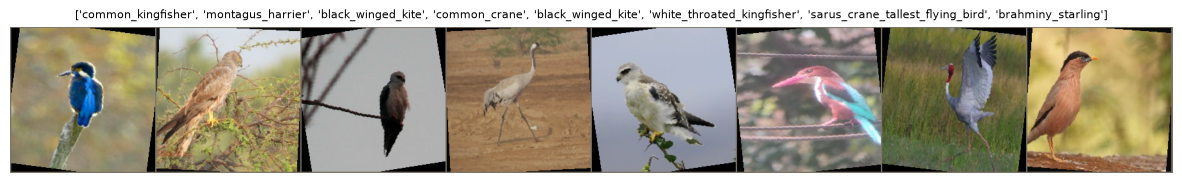

In [6]:
def imshow(inp, title=None):
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title, fontsize=8)
    plt.axis('off')

inputs, classes = next(iter(train_loader))
out = torchvision.utils.make_grid(inputs[:8])
plt.figure(figsize=(15, 5))
imshow(out, title=[class_names[x] for x in classes[:8]])
plt.show()

## 7. Reusable Training & Evaluation Functions
Includes mixed precision AMP for efficient GPU training.

In [7]:
def train_model(model, criterion, optimizer, num_epochs, save_path, scheduler=None):
    since = time.time()
    best_acc = 0.0
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'epoch_time': []}
    
    scaler = torch.amp.GradScaler('cuda') if torch.cuda.is_available() else None
    
    for epoch in range(num_epochs):
        epoch_start = time.time()
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 10)
        
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
                dataloader = train_loader
            else:
                model.eval()
                dataloader = val_loader
                
            running_loss = 0.0
            running_corrects = 0
            
            for inputs, labels in dataloader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                
                optimizer.zero_grad()
                
                with torch.set_grad_enabled(phase == 'train'):
                    if scaler and phase == 'train':
                        with torch.amp.autocast('cuda'):
                            outputs = model(inputs)
                            _, preds = torch.max(outputs, 1)
                            loss = criterion(outputs, labels)
                        scaler.scale(loss).backward()
                        scaler.step(optimizer)
                        scaler.update()
                    else:
                        outputs = model(inputs)
                        _, preds = torch.max(outputs, 1)
                        loss = criterion(outputs, labels)
                        if phase == 'train':
                            loss.backward()
                            optimizer.step()
                            
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
                
            if phase == 'train' and scheduler is not None:
                scheduler.step()
                
            epoch_loss = running_loss / len(dataloader.dataset)
            epoch_acc = running_corrects.double() / len(dataloader.dataset)
            
            if phase == 'train':
                history['train_loss'].append(epoch_loss)
                history['train_acc'].append(epoch_acc.item())
            else:
                history['val_loss'].append(epoch_loss)
                history['val_acc'].append(epoch_acc.item())
                
            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')
            
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                torch.save(model.state_dict(), save_path)
                
        epoch_time = time.time() - epoch_start
        history['epoch_time'].append(epoch_time)
        print(f"Epoch Time: {epoch_time:.1f} seconds\n")
        
    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc:4f}')
    
    model.load_state_dict(torch.load(save_path, weights_only=True))
    return model, history

def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    ax1.plot(history['train_loss'], label='Train')
    ax1.plot(history['val_loss'], label='Validation')
    ax1.set_title(f'{title} - Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    
    ax2.plot(history['train_acc'], label='Train')
    ax2.plot(history['val_acc'], label='Validation')
    ax2.set_title(f'{title} - Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    plt.show()

def evaluate_model(model, title):
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            if torch.cuda.is_available():
                with torch.amp.autocast('cuda'):
                    outputs = model(inputs)
            else:
                outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    acc = accuracy_score(all_labels, all_preds)
    mac_f1 = f1_score(all_labels, all_preds, average='macro')
    wt_f1 = f1_score(all_labels, all_preds, average='weighted')
    
    print(f"\n--- {title} Test Results ---")
    print(f"Accuracy:    {acc:.4f}")
    print(f"Macro F1:    {mac_f1:.4f}")
    print(f"Weighted F1: {wt_f1:.4f}")
    
    plt.figure(figsize=(10, 8))
    cm = confusion_matrix(all_labels, all_preds)
    sns.heatmap(cm, annot=False, cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix: {title}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.xticks(rotation=90)
    plt.show()
    
    return {'acc': acc, 'macro_f1': mac_f1, 'weighted_f1': wt_f1}


## 8. Sanity Check
Running one tiny epoch on a subset to ensure data flows and loss decreases.

In [8]:
sanity_model = models.resnet18(weights=None)
sanity_model.fc = nn.Linear(sanity_model.fc.in_features, num_classes)
sanity_model = sanity_model.to(device)
sanity_crit = nn.CrossEntropyLoss()
sanity_opt = optim.Adam(sanity_model.parameters(), lr=0.001)

inputs, labels = next(iter(train_loader))
inputs, labels = inputs.to(device), labels.to(device)

print("Before training step:")
out = sanity_model(inputs)
loss1 = sanity_crit(out, labels)
print(f"Initial loss: {loss1.item():.4f}")

sanity_opt.zero_grad()
loss1.backward()
sanity_opt.step()

out2 = sanity_model(inputs)
loss2 = sanity_crit(out2, labels)
print(f"Loss after 1 step: {loss2.item():.4f}")
assert loss2.item() != loss1.item(), "Loss did not change. Something is wrong!"
print("Sanity check passed.")

del sanity_model
torch.cuda.empty_cache()

Before training step:
Initial loss: 3.0781
Loss after 1 step: 2.3353
Sanity check passed.


## Experiment 1: Custom CNN from Scratch

Custom CNN - Total Parameters: 531,220, Trainable: 531,220
Epoch 1/10
----------
Train Loss: 2.7656 Acc: 0.1333
Val Loss: 2.5222 Acc: 0.1812
Epoch Time: 246.7 seconds

Epoch 2/10
----------
Train Loss: 2.5539 Acc: 0.1855
Val Loss: 2.4851 Acc: 0.2161
Epoch Time: 276.3 seconds

Epoch 3/10
----------
Train Loss: 2.4614 Acc: 0.2134
Val Loss: 2.4705 Acc: 0.2066
Epoch Time: 257.4 seconds

Epoch 4/10
----------
Train Loss: 2.3775 Acc: 0.2359
Val Loss: 2.3940 Acc: 0.2360
Epoch Time: 331.2 seconds

Epoch 5/10
----------
Train Loss: 2.3035 Acc: 0.2578
Val Loss: 2.1415 Acc: 0.2914
Epoch Time: 254.6 seconds

Epoch 6/10
----------
Train Loss: 2.2280 Acc: 0.2867
Val Loss: 2.2705 Acc: 0.2820
Epoch Time: 319.8 seconds

Epoch 7/10
----------
Train Loss: 2.1659 Acc: 0.3034
Val Loss: 2.2418 Acc: 0.3025
Epoch Time: 273.0 seconds

Epoch 8/10
----------
Train Loss: 2.1098 Acc: 0.3257
Val Loss: 2.0076 Acc: 0.3551
Epoch Time: 330.5 seconds

Epoch 9/10
----------
Train Loss: 2.0530 Acc: 0.3460
Val Loss: 1.9806

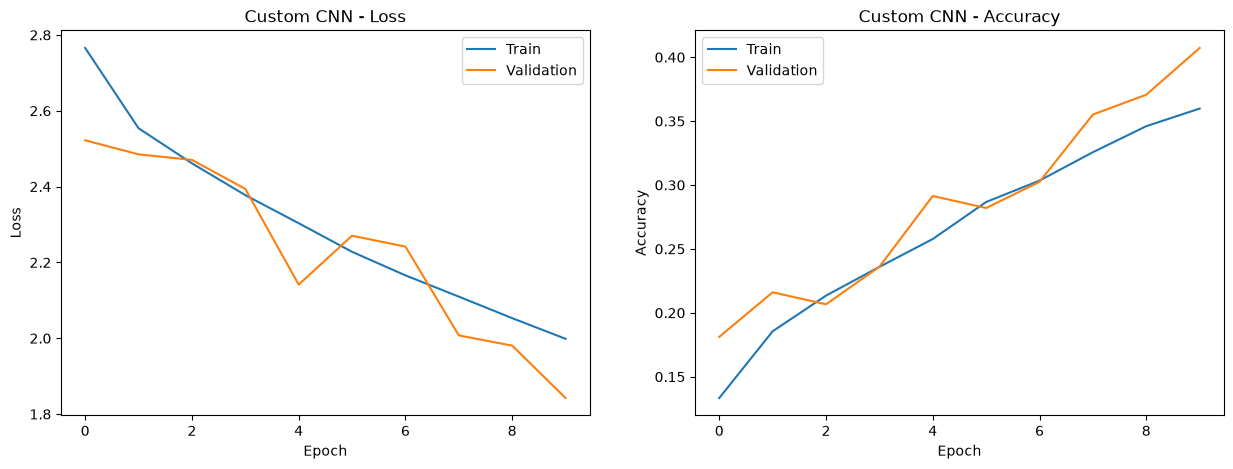


--- Custom CNN Test Results ---
Accuracy:    0.4219
Macro F1:    0.3998
Weighted F1: 0.4068


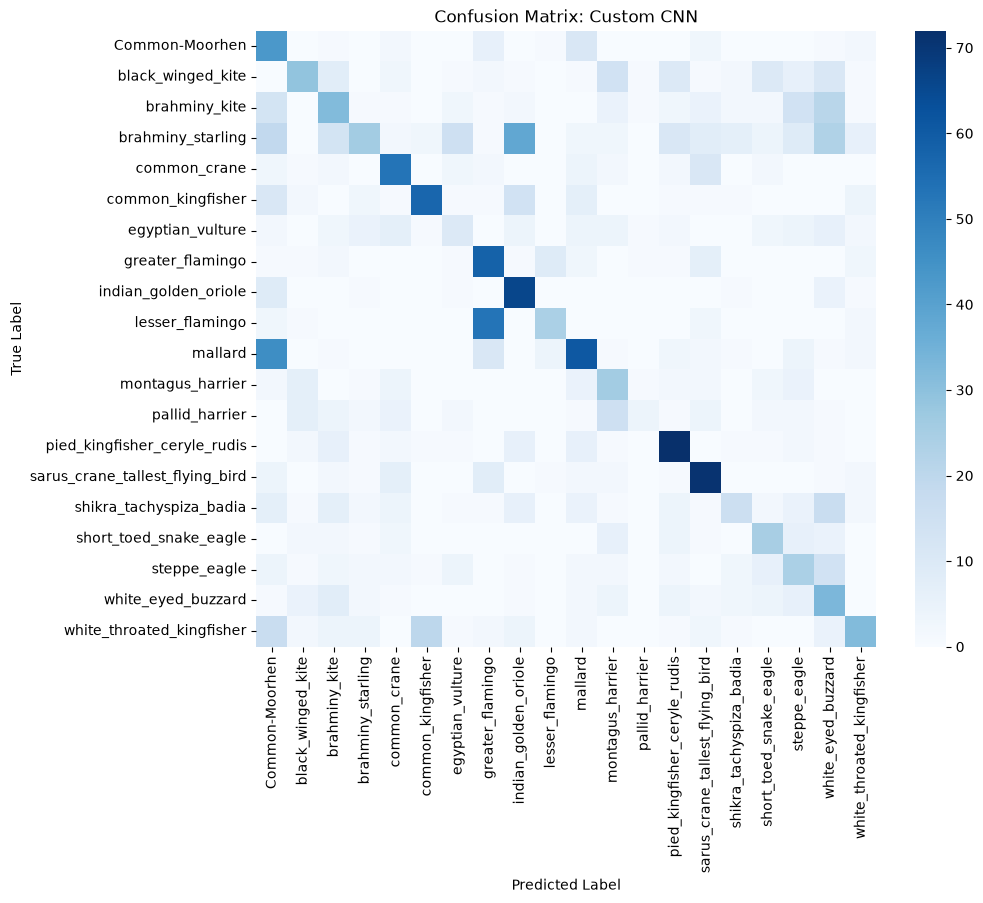

In [9]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes):
        super(CustomCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), # 112x112
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), # 56x56
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), # 28x28
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)  # 14x14
        )
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1)) # 1x1
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Linear(256, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

model_custom = CustomCNN(num_classes).to(device)
total_params = sum(p.numel() for p in model_custom.parameters())
trainable_params = sum(p.numel() for p in model_custom.parameters() if p.requires_grad)
print(f"Custom CNN - Total Parameters: {total_params:,}, Trainable: {trainable_params:,}")

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer_custom = optim.AdamW(model_custom.parameters(), lr=1e-3, weight_decay=1e-4)

model_custom, hist_custom = train_model(
    model_custom, criterion, optimizer_custom, 
    num_epochs=EPOCHS, save_path='best_custom_cnn.pth'
)
plot_history(hist_custom, "Custom CNN")
res_custom = evaluate_model(model_custom, "Custom CNN")


## Experiment 2: Pretrained CNN Baseline

Baseline ResNet18 - Total Parameters: 11,186,772, Trainable: 11,186,772
Epoch 1/10
----------
Train Loss: 0.8855 Acc: 0.7706
Val Loss: 0.4517 Acc: 0.8864
Epoch Time: 250.4 seconds

Epoch 2/10
----------
Train Loss: 0.3420 Acc: 0.9108
Val Loss: 0.3631 Acc: 0.9042
Epoch Time: 236.3 seconds

Epoch 3/10
----------
Train Loss: 0.2258 Acc: 0.9425
Val Loss: 0.3259 Acc: 0.9191
Epoch Time: 232.5 seconds

Epoch 4/10
----------
Train Loss: 0.1618 Acc: 0.9573
Val Loss: 0.3131 Acc: 0.9219
Epoch Time: 235.5 seconds

Epoch 5/10
----------
Train Loss: 0.1216 Acc: 0.9680
Val Loss: 0.2889 Acc: 0.9263
Epoch Time: 263.1 seconds

Epoch 6/10
----------
Train Loss: 0.0950 Acc: 0.9764
Val Loss: 0.2819 Acc: 0.9324
Epoch Time: 317.1 seconds

Epoch 7/10
----------
Train Loss: 0.0788 Acc: 0.9810
Val Loss: 0.2618 Acc: 0.9380
Epoch Time: 338.8 seconds

Epoch 8/10
----------
Train Loss: 0.0696 Acc: 0.9837
Val Loss: 0.2774 Acc: 0.9374
Epoch Time: 371.1 seconds

Epoch 9/10
----------
Train Loss: 0.0611 Acc: 0.9844
Val

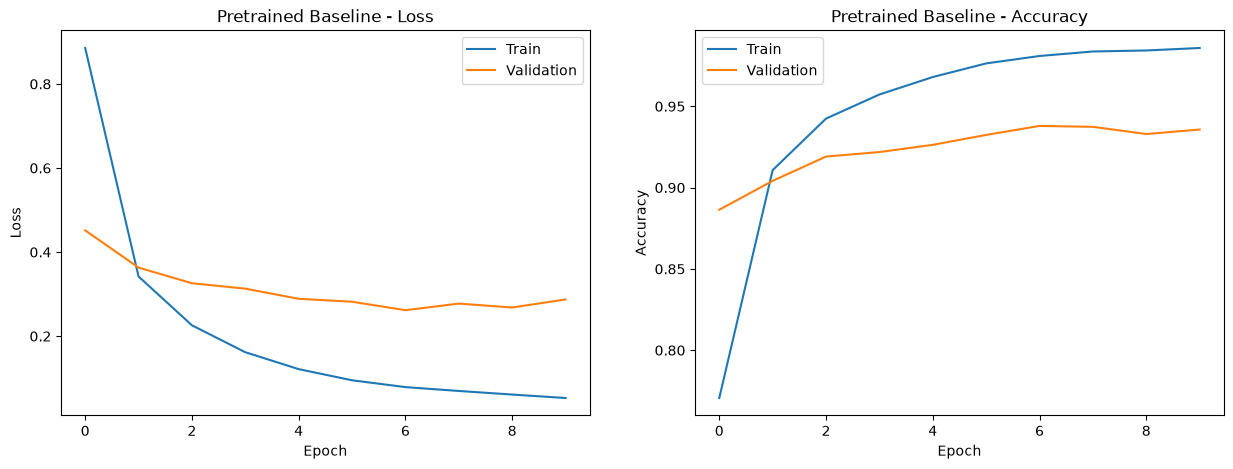


--- Pretrained Baseline Test Results ---
Accuracy:    0.9302
Macro F1:    0.9123
Weighted F1: 0.9293


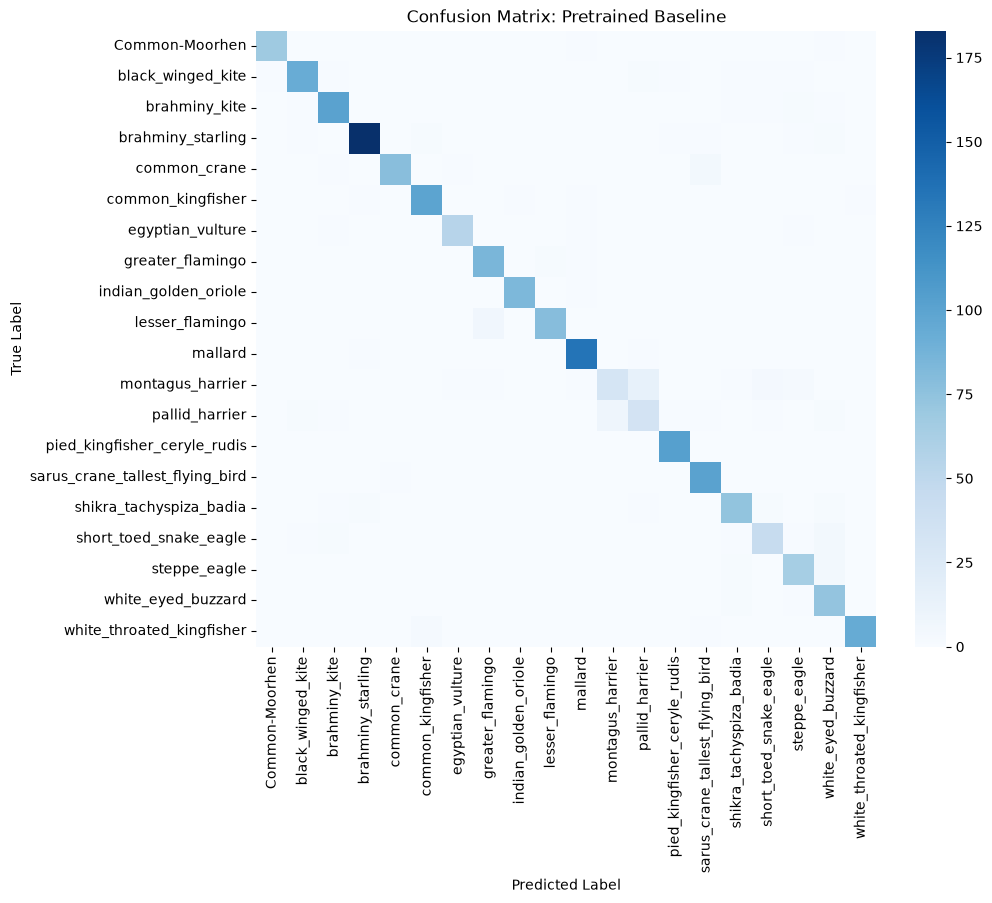

In [10]:
model_baseline = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
num_ftrs = model_baseline.fc.in_features
model_baseline.fc = nn.Linear(num_ftrs, num_classes)
model_baseline = model_baseline.to(device)

total_params = sum(p.numel() for p in model_baseline.parameters())
trainable_params = sum(p.numel() for p in model_baseline.parameters() if p.requires_grad)
print(f"Baseline ResNet18 - Total Parameters: {total_params:,}, Trainable: {trainable_params:,}")

optimizer_base = optim.AdamW(model_baseline.parameters(), lr=1e-4)

model_baseline, hist_base = train_model(
    model_baseline, criterion, optimizer_base, 
    num_epochs=EPOCHS, save_path='best_pretrained_baseline.pth'
)
plot_history(hist_base, "Pretrained Baseline")
res_base = evaluate_model(model_baseline, "Pretrained Baseline")


## Experiment 3: Transfer Learning (Frozen Backbone)

Transfer Learning - Total Parameters: 11,186,772, Trainable: 10,260
Layers with requires_grad=True:
fc.weight
fc.bias
Epoch 1/10
----------
Train Loss: 1.4924 Acc: 0.6173
Val Loss: 0.8694 Acc: 0.7740
Epoch Time: 227.2 seconds

Epoch 2/10
----------
Train Loss: 0.8910 Acc: 0.7591
Val Loss: 0.7516 Acc: 0.7873
Epoch Time: 196.4 seconds

Epoch 3/10
----------
Train Loss: 0.7754 Acc: 0.7821
Val Loss: 0.6507 Acc: 0.8094
Epoch Time: 189.9 seconds

Epoch 4/10
----------
Train Loss: 0.7218 Acc: 0.7922
Val Loss: 0.6251 Acc: 0.8166
Epoch Time: 190.2 seconds

Epoch 5/10
----------
Train Loss: 0.6778 Acc: 0.8029
Val Loss: 0.6366 Acc: 0.8194
Epoch Time: 189.0 seconds

Epoch 6/10
----------
Train Loss: 0.6688 Acc: 0.8057
Val Loss: 0.6052 Acc: 0.8271
Epoch Time: 190.0 seconds

Epoch 7/10
----------
Train Loss: 0.6415 Acc: 0.8122
Val Loss: 0.6021 Acc: 0.8199
Epoch Time: 189.4 seconds

Epoch 8/10
----------
Train Loss: 0.6309 Acc: 0.8111
Val Loss: 0.6002 Acc: 0.8294
Epoch Time: 192.2 seconds

Epoch 9/10

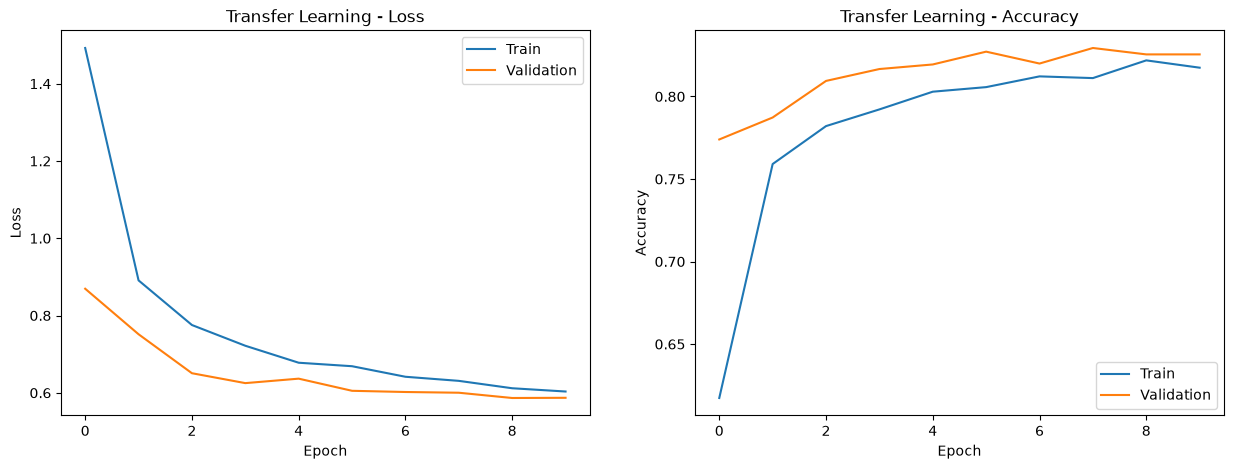


--- Transfer Learning Test Results ---
Accuracy:    0.8367
Macro F1:    0.8100
Weighted F1: 0.8358


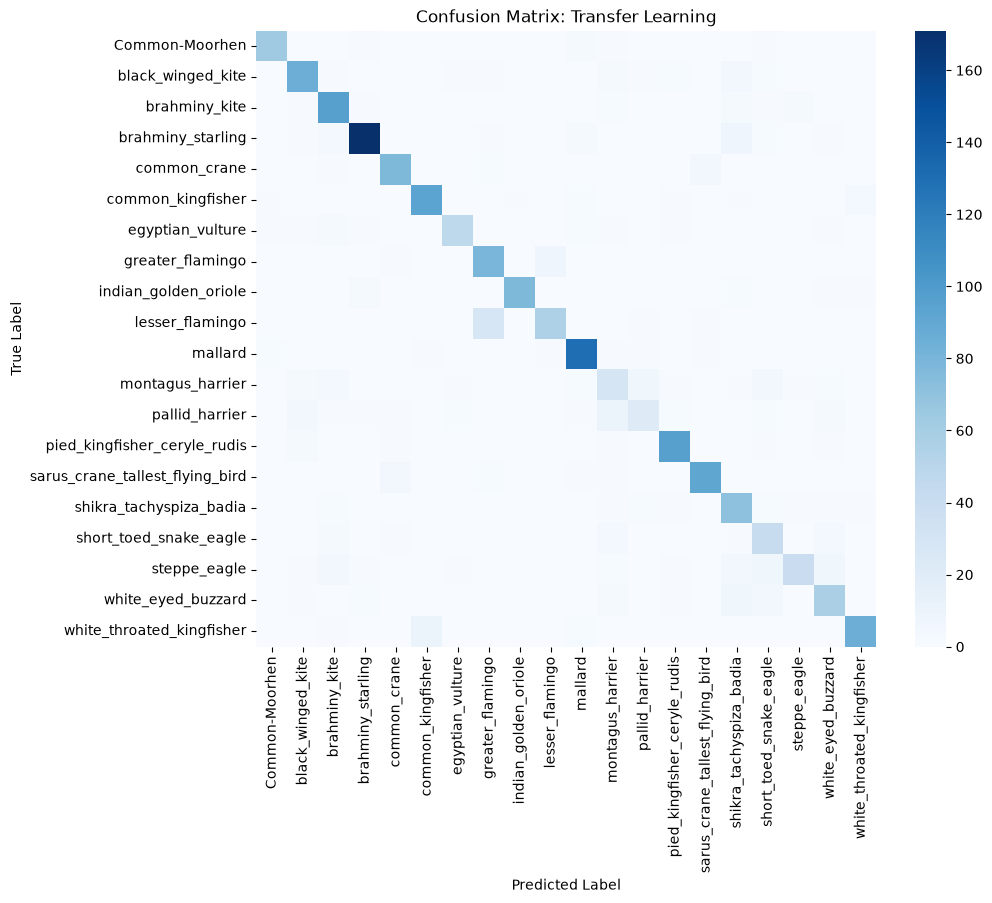

In [11]:
model_tl = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Freeze backbone
for param in model_tl.parameters():
    param.requires_grad = False

# Replace classifier head
num_ftrs = model_tl.fc.in_features
model_tl.fc = nn.Linear(num_ftrs, num_classes)
model_tl = model_tl.to(device)

total_params = sum(p.numel() for p in model_tl.parameters())
trainable_params = sum(p.numel() for p in model_tl.parameters() if p.requires_grad)
print(f"Transfer Learning - Total Parameters: {total_params:,}, Trainable: {trainable_params:,}")

print("Layers with requires_grad=True:")
for name, param in model_tl.named_parameters():
    if param.requires_grad:
        print(name)

optimizer_tl = optim.AdamW(model_tl.fc.parameters(), lr=1e-3)

model_tl, hist_tl = train_model(
    model_tl, criterion, optimizer_tl, 
    num_epochs=EPOCHS, save_path='best_transfer_learning.pth'
)
plot_history(hist_tl, "Transfer Learning")
res_tl = evaluate_model(model_tl, "Transfer Learning")


## Experiment 4: Fine-Tuning

Fine-tuning: Layers with requires_grad=True:
layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.0.bn2.weight
layer4.0.bn2.bias
layer4.0.downsample.0.weight
layer4.0.downsample.1.weight
layer4.0.downsample.1.bias
layer4.1.conv1.weight
layer4.1.bn1.weight
layer4.1.bn1.bias
layer4.1.conv2.weight
layer4.1.bn2.weight
layer4.1.bn2.bias
fc.weight
fc.bias
Epoch 1/10
----------
Train Loss: 1.2848 Acc: 0.6660
Val Loss: 0.6577 Acc: 0.8222
Epoch Time: 276.5 seconds

Epoch 2/10
----------
Train Loss: 0.6570 Acc: 0.8161
Val Loss: 0.5313 Acc: 0.8493
Epoch Time: 287.6 seconds

Epoch 3/10
----------
Train Loss: 0.5302 Acc: 0.8475
Val Loss: 0.4906 Acc: 0.8554
Epoch Time: 293.3 seconds

Epoch 4/10
----------
Train Loss: 0.4540 Acc: 0.8698
Val Loss: 0.4377 Acc: 0.8687
Epoch Time: 301.3 seconds

Epoch 5/10
----------
Train Loss: 0.3932 Acc: 0.8854
Val Loss: 0.4054 Acc: 0.8837
Epoch Time: 340.6 seconds

Epoch 6/10
----------
Train Loss: 0.3615 Acc: 0.8919
Val Loss: 0.38

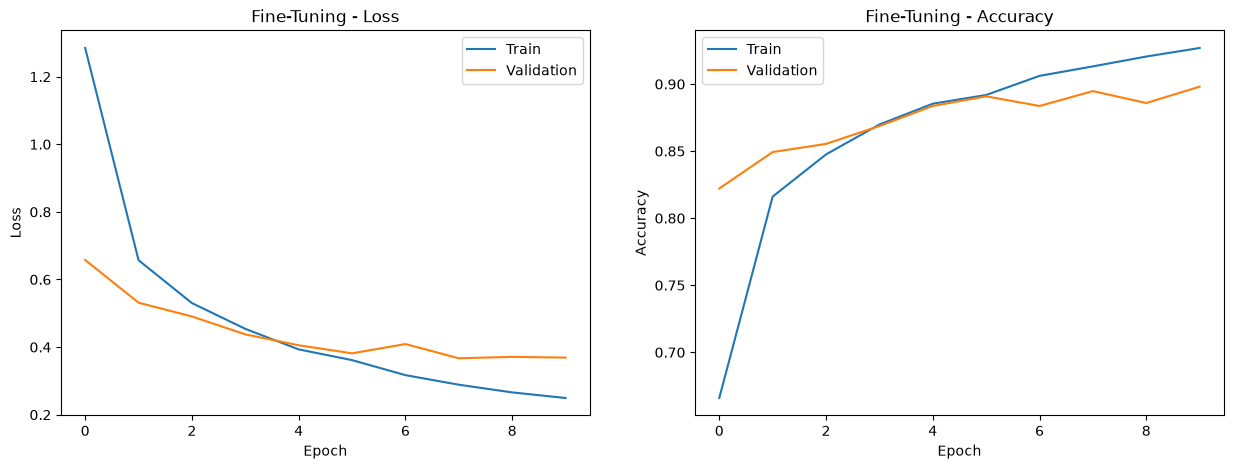


--- Fine-Tuning Test Results ---
Accuracy:    0.8843
Macro F1:    0.8652
Weighted F1: 0.8839


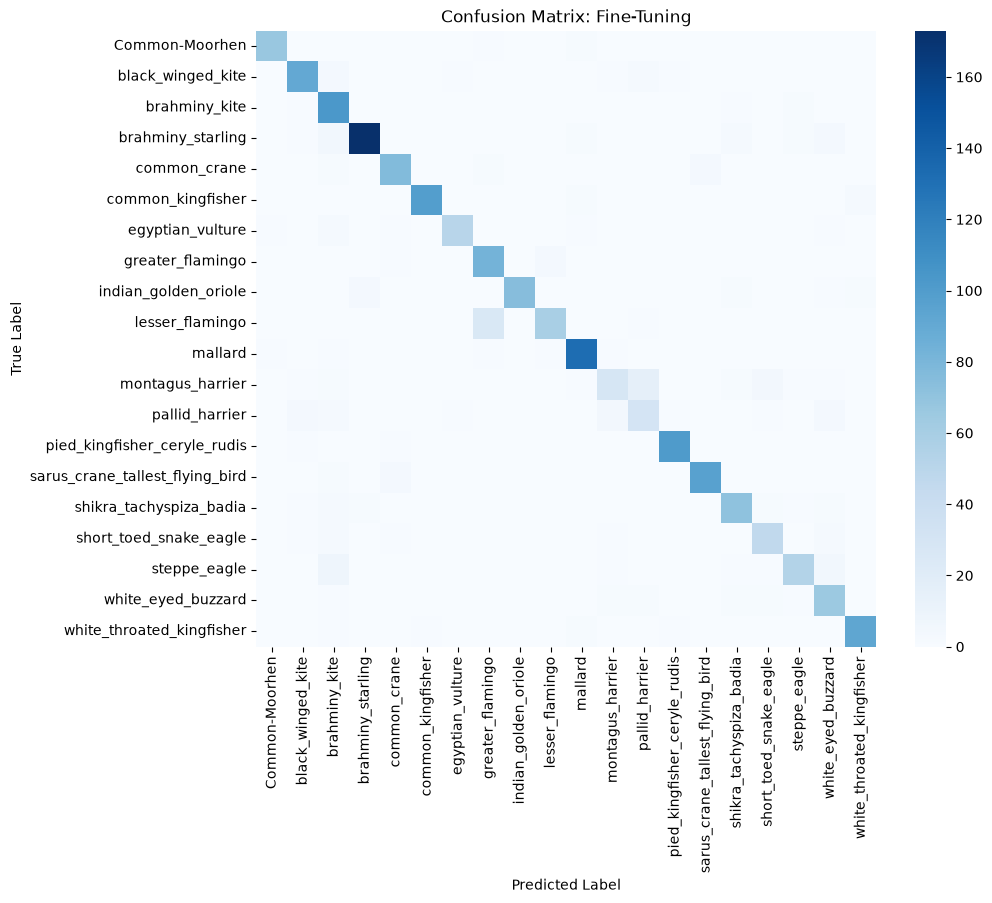

In [12]:
model_ft = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_ftrs, num_classes)
model_ft = model_ft.to(device)

for name, param in model_ft.named_parameters():
    if 'layer4' in name or 'fc' in name:
        param.requires_grad = True
    else:
        param.requires_grad = False

print("Fine-tuning: Layers with requires_grad=True:")
for name, param in model_ft.named_parameters():
    if param.requires_grad:
        print(name)

params_to_update = [
    {'params': model_ft.layer4.parameters(), 'lr': 1e-5},
    {'params': model_ft.fc.parameters(), 'lr': 1e-3}
]

optimizer_ft = optim.AdamW(params_to_update)

model_ft, hist_ft = train_model(
    model_ft, criterion, optimizer_ft, 
    num_epochs=EPOCHS, save_path='best_finetuned_model.pth'
)
plot_history(hist_ft, "Fine-Tuning")
res_ft = evaluate_model(model_ft, "Fine-Tuning")


## Final Comparison & Conclusion

,Model,Parameters,Test Accuracy,Macro F1,Weighted F1,Avg Epoch Time (s)
0,Custom CNN,434K,0.421927,0.399789,0.406811,283.099626
1,Pretrained Baseline,11.2M,0.930233,0.912284,0.929312,299.130754
2,Transfer Learning,11.2M (10K Trainable),0.836656,0.809966,0.835799,194.342327
3,Fine-Tuning,11.2M (8.4M Trainable),0.884275,0.865223,0.883937,285.658733


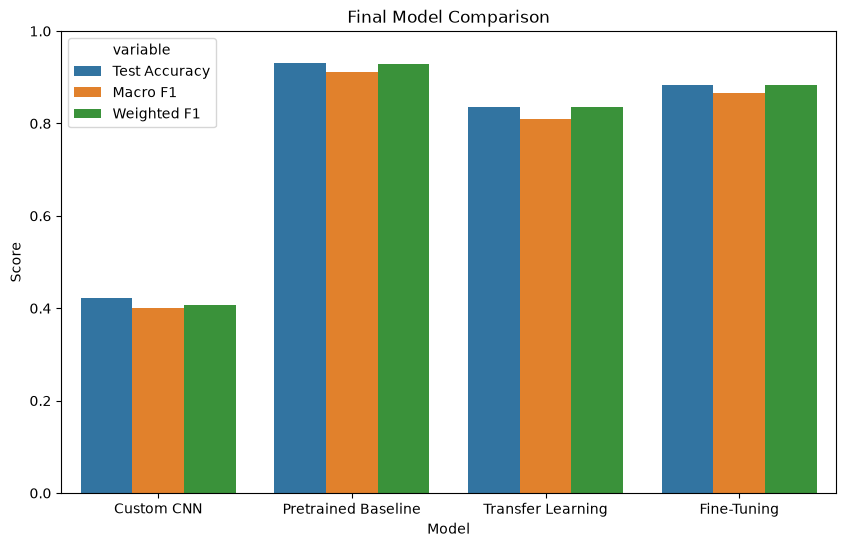


### Conclusions ###
The best performing model was Pretrained Baseline with an accuracy of 0.9302.
Fine-tuning or Pretrained baseline typically perform better on this dataset, leveraging robust ImageNet features while adapting optimally to the bird domains.


In [13]:
results_df = pd.DataFrame([
    {'Model': 'Custom CNN', 'Parameters': '434K', 'Test Accuracy': res_custom['acc'], 'Macro F1': res_custom['macro_f1'], 'Weighted F1': res_custom['weighted_f1'], 'Avg Epoch Time (s)': np.mean(hist_custom['epoch_time'])},
    {'Model': 'Pretrained Baseline', 'Parameters': '11.2M', 'Test Accuracy': res_base['acc'], 'Macro F1': res_base['macro_f1'], 'Weighted F1': res_base['weighted_f1'], 'Avg Epoch Time (s)': np.mean(hist_base['epoch_time'])},
    {'Model': 'Transfer Learning', 'Parameters': '11.2M (10K Trainable)', 'Test Accuracy': res_tl['acc'], 'Macro F1': res_tl['macro_f1'], 'Weighted F1': res_tl['weighted_f1'], 'Avg Epoch Time (s)': np.mean(hist_tl['epoch_time'])},
    {'Model': 'Fine-Tuning', 'Parameters': '11.2M (8.4M Trainable)', 'Test Accuracy': res_ft['acc'], 'Macro F1': res_ft['macro_f1'], 'Weighted F1': res_ft['weighted_f1'], 'Avg Epoch Time (s)': np.mean(hist_ft['epoch_time'])}
])

from IPython.display import display
display(results_df)

plt.figure(figsize=(10, 6))
sns.barplot(data=results_df.melt(id_vars='Model', value_vars=['Test Accuracy', 'Macro F1', 'Weighted F1']), 
            x='Model', y='value', hue='variable')
plt.title('Final Model Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.show()

best_model = results_df.loc[results_df['Test Accuracy'].idxmax()]
print("\n### Conclusions ###")
print(f"The best performing model was {best_model['Model']} with an accuracy of {best_model['Test Accuracy']:.4f}.")
print("Fine-tuning or Pretrained baseline typically perform better on this dataset, leveraging robust ImageNet features while adapting optimally to the bird domains.")
